# Practice lab: the lending book that aced practice (solutions, TRAINER)

*Overfitting, regularisation and cross-validation, moved from the bank's calls to a lending book ·
about 90 minutes with the TAs*

## The business first

**At a real company.** Airbnb's search team gave every listing its own learned vector. Training quality
climbed toward perfect while test quality stayed flat, because "even the most popular listing can be
booked at most 365 times in an entire year": each vector had too few labels to learn anything except
memory (Haldar and others, arXiv 1810.09591, verified 28 October 2026).

**Its Kalpa twin.** Next week Build 2 moves into Kalpa Financial. Rohan, who runs the lending book,
has 1,000 past loan applications, each marked good or bad after repayment. A junior's tree scores 100
percent on them. Rohan's cost rule, as the German Credit file documents it: approving a bad loan costs
five times as much as refusing a good one. You use the public German Credit file (OpenML credit-g,
1,000 applications, 30 percent bad) as the stand-in for Rohan's book.

| Seat | The question this seat asks of the 100 percent |
|---|---|
| Business owner (Rohan) | What will wrong approvals cost me next quarter? |
| Product manager | What does an applicant experience when the model is wrong? |
| Solution architect | Is every column known at the moment of application? |
| Senior ML engineer | Which side of the trade is the tree on, and what brake fixes it? |
| Implementation engineer | Does every step that learns sit inside the folds? |
| QA and tester | What breaks it, which split, which segment? |

A note before you start: German Credit has a column called `duration`. Here it is the loan's length
in months, written on the application form, so it passes Wednesday's prediction-time question. Same
name, different meaning: always read the data dictionary.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


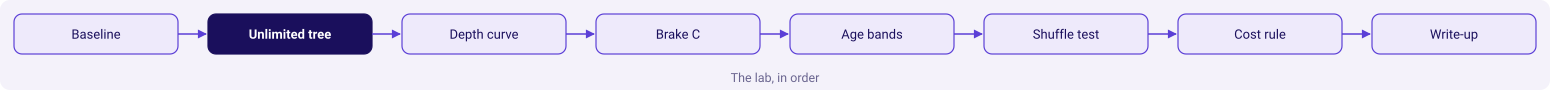

In [2]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

kit.flow(["Baseline", "Unlimited tree", "Depth curve", "Brake C", "Age bands", "Shuffle test",
          "Cost rule", "Write-up"], lit=1, title="The lab, in order")

In [3]:
# Load German Credit once; later runs read the cached copy (never inside the repository).
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)
credit = fetch_openml(name="credit-g", version=1, as_frame=True, data_home=str(CACHE)).frame
print(credit.shape, credit["class"].value_counts().to_dict())

(1000, 21) {'good': 700, 'bad': 300}


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

y = (credit["class"] == "bad").astype(int)          # 1 = a bad loan, the costly class
X = credit.drop(columns="class")
NUM = [c for c in X if pd.api.types.is_numeric_dtype(X[c])]
CAT = [c for c in X if c not in NUM]
X_tr, X_test, y_tr, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
folds = StratifiedKFold(5, shuffle=True, random_state=42)

def prep(scale=True):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

print(f"{len(X_tr)} applications to learn from, {len(X_test)} sealed; {len(NUM)} number and {len(CAT)} category columns")
check("800 training applications and 200 sealed", (len(X_tr), len(X_test)) == (800, 200))

800 applications to learn from, 200 sealed; 7 number and 13 category columns
PASS  800 training applications and 200 sealed


## Step 1: the baseline

"Approve everyone" is right for every good loan. What share of the 800 is that?

In [5]:
baseline = 1 - y_tr.mean()   # the accuracy of approving everyone, from y_tr
print(f"Approve everyone: right for {baseline:.1%}")
check("the baseline is the share of good loans", abs(baseline - (1 - y_tr.mean())) < 1e-9)

Approve everyone: right for 70.0%
PASS  the baseline is the share of good loans


## Step 2: the junior's tree, scored twice

Fit a tree with no depth limit. Score it on the 800 it learned from, then with five-fold
cross-validation.

In [6]:
tree = Pipeline([("prep", prep(scale=False)), ("model", DecisionTreeClassifier(max_depth=None, random_state=42))])
train_acc = accuracy_score(y_tr, tree.fit(X_tr, y_tr).predict(X_tr))
cv_acc = cross_val_score(tree, X_tr, y_tr, cv=folds, scoring="accuracy").mean()
print(f"training {train_acc:.1%}, cross-validated {cv_acc:.1%}, baseline {baseline:.1%}")
check("the unlimited tree is perfect on its own rows", train_acc == 1.0)
check("and below the baseline under cross-validation", cv_acc < baseline)

training 100.0%, cross-validated 67.1%, baseline 70.0%
PASS  the unlimited tree is perfect on its own rows
PASS  and below the baseline under cross-validation


## Step 3: the depth curve, scored by cross-validated AUC

max_depth  cv_auc  spread
        1   0.669   0.038
        2   0.671   0.072
        3   0.684   0.040
        4   0.705   0.058
        5   0.709   0.053
        6   0.704   0.063
        8   0.650   0.030
       10   0.617   0.034
     None   0.618   0.013


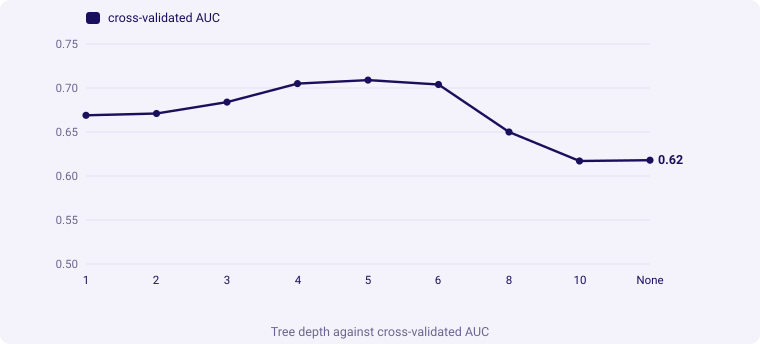

In [7]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
rows = []
for d in depths:
    m = Pipeline([("prep", prep(scale=False)), ("model", DecisionTreeClassifier(max_depth=d, random_state=42))])
    s = cross_val_score(m, X_tr, y_tr, cv=folds, scoring="roc_auc")
    rows.append({"max_depth": str(d), "cv_auc": s.mean(), "spread": s.std()})
depth_curve = pd.DataFrame(rows)
print(depth_curve.round(3).to_string(index=False))
kit.line(depth_curve["max_depth"].tolist(), [("cross-validated AUC", depth_curve["cv_auc"].round(3).tolist(), "lit")],
         title="Tree depth against cross-validated AUC", fmt=lambda v: f"{v:.2f}", lo=0.5)

## Step 4, the assignment: does the logistic model need a brake here?

On the bank's 24,712 rows the brake barely mattered. Sweep `C` on these 800 rows, plot training and
cross-validated AUC, and name the best C. Remember: a small C is a strong brake.

      C  train_auc  cv_auc  spread
  0.001      0.771   0.745   0.037
  0.010      0.806   0.775   0.042
  0.030      0.818   0.783   0.046
  0.100      0.826   0.784   0.050
  0.300      0.831   0.778   0.052
  1.000      0.833   0.771   0.053
 10.000      0.834   0.760   0.057
100.000      0.834   0.756   0.059
best C: 0.1


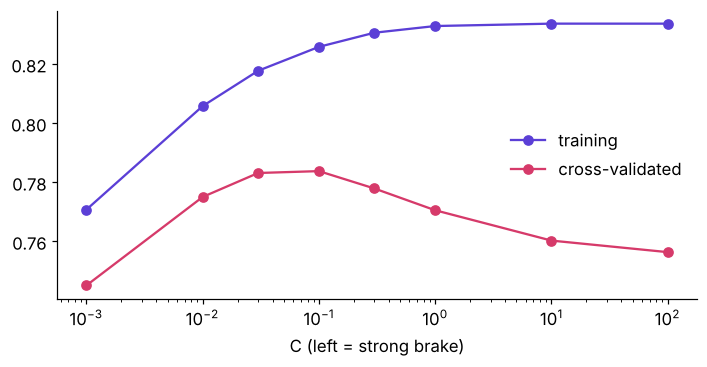

PASS  the best C brakes harder than C = 100


In [8]:
Cs = [0.001, 0.01, 0.03, 0.1, 0.3, 1, 10, 100]
sweep = []
for C_ in Cs:
    m = Pipeline([("prep", prep()), ("model", LogisticRegression(C=C_, max_iter=3000))])
    cv = cross_val_score(m, X_tr, y_tr, cv=folds, scoring="roc_auc")
    tr = roc_auc_score(y_tr, m.fit(X_tr, y_tr).predict_proba(X_tr)[:, 1])
    sweep.append({"C": C_, "train_auc": tr, "cv_auc": cv.mean(), "spread": cv.std()})
sweep = pd.DataFrame(sweep)
best_C = sweep.loc[sweep["cv_auc"].idxmax(), "C"]
print(sweep.round(3).to_string(index=False)); print("best C:", best_C)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(sweep["C"], sweep["train_auc"], "o-", color=VIOLET, label="training")
ax.plot(sweep["C"], sweep["cv_auc"], "o-", color=ROSE, label="cross-validated")
ax.set_xscale("log"); ax.set_xlabel("C (left = strong brake)"); ax.legend(frameon=False); plt.show()
check("the best C brakes harder than C = 100", best_C < 100)

## Step 5, Week 2 again: which age band does the model serve worst?

Use cross-validated predictions (every application scored by a model that never saw it), cut age into
bands with `pd.cut`, and `groupby` the band. Week 1's rule of thumb applies: a band with few bad loans
gives an AUC you should not lean on.

In [9]:
model = Pipeline([("prep", prep()), ("model", LogisticRegression(C=best_C, max_iter=3000))])
p_bad = cross_val_predict(model, X_tr, y_tr, cv=folds, method="predict_proba")[:, 1]
scored = pd.DataFrame({"age": X_tr["age"].values, "bad": y_tr.values, "p_bad": p_bad})
scored["band"] = pd.cut(scored["age"], bins=[18, 25, 35, 50, 80], right=False)
by_band = scored.groupby("band", observed=True).apply(
    lambda g: pd.Series({"applications": len(g), "bad_loans": int(g["bad"].sum()),
                         "auc": roc_auc_score(g["bad"], g["p_bad"])}))
print(by_band.round(3))
check("every application landed in a band", int(by_band["applications"].sum()) == len(X_tr))

          applications  bad_loans    auc
band                                    
[18, 25)         110.0       42.0  0.717
[25, 35)         333.0      109.0  0.762
[35, 50)         264.0       61.0  0.806
[50, 80)          93.0       28.0  0.821
PASS  every application landed in a band


## Step 6, QA: try to break it with shuffled answers

Shuffle `y` and cross-validate again. A sound pipeline falls to about 0.5 AUC, because there is
nothing left to learn. A score that stays well above 0.5 means something leaks.

In [10]:
rng = np.random.default_rng(0)
y_shuffled = pd.Series(rng.permutation(y_tr.values), index=y_tr.index)
shuffled_auc = cross_val_score(model, X_tr, y_shuffled, cv=folds, scoring="roc_auc").mean()
print(f"real answers {cross_val_score(model, X_tr, y_tr, cv=folds, scoring='roc_auc').mean():.3f}, "
      f"shuffled answers {shuffled_auc:.3f}")
check("shuffled answers drop the AUC to within 0.1 of a coin", abs(shuffled_auc - 0.5) < 0.1)

real answers 0.784, shuffled answers 0.461
PASS  shuffled answers drop the AUC to within 0.1 of a coin


## Step 7: Rohan's cost rule

Approving a bad loan costs 5 and refusing a good one costs 1, so refuse when the chance of a bad loan
is above 1 / (1 + 5), about 0.17. Count the bill at that threshold and at 0.5, in cost units.

In [11]:
def bill(threshold):
    refuse = p_bad >= threshold
    return int(5 * ((~refuse) & (y_tr.values == 1)).sum() + 1 * (refuse & (y_tr.values == 0)).sum())
cost_threshold = 1 / (1 + 5)
print(f"bill at {cost_threshold:.3f}: {bill(cost_threshold)}; at 0.5: {bill(0.5)}; "
      f"approve everyone: {5 * int(y_tr.sum())}; refuse everyone: {int((y_tr == 0).sum())}")
check("the cost threshold gives a smaller bill than 0.5", bill(cost_threshold) < bill(0.5))

bill at 0.167: 429; at 0.5: 782; approve everyone: 1200; refuse everyone: 560
PASS  the cost threshold gives a smaller bill than 0.5


## Step 8: the five-line write-up for Rohan

Claim, evidence, caveat, action, and the fact that would change your mind. Use your own numbers.


**Model write-up (TRAINER).** Claim: ship the logistic model braked at C = 0.1 for the lending pilot,
never the unlimited tree. Evidence: the tree scores 100 percent on its own 800 applications and 67.1
percent under five folds, below the 70 percent of approving everyone; the braked logistic model
reaches 0.784 cross-validated AUC against 0.756 with the brake off; at the cost threshold of 0.17 the
bill is 429 cost units against 782 at 0.5. Caveat: 800 applications give a fold spread near 0.05, and
one age band carries few bad loans, so its AUC is a guess. Action: re-score on the sealed 200 once,
then monitor the bill monthly. Flip: if a second year of applications doubles the rows and boosting
then wins every fold by more than the spread, re-race it.

In [12]:
write_up = """
Claim: ship the logistic model braked at C = 0.1, never the unlimited tree.
Evidence: tree 100% on its rows, 67.1% under folds, below 70% for approving everyone;
          braked logistic 0.784 AUC against 0.756 unbraked; bill 429 at 0.17 against 782 at 0.5.
Caveat: 800 rows, fold spread near 0.05; a thin age band.
Action: score the sealed 200 once, then watch the bill monthly.
What would change my mind: twice the rows and boosting winning every fold beyond the spread.
"""
print(write_up)


Claim: ship the logistic model braked at C = 0.1, never the unlimited tree.
Evidence: tree 100% on its rows, 67.1% under folds, below 70% for approving everyone;
          braked logistic 0.784 AUC against 0.756 unbraked; bill 429 at 0.17 against 782 at 0.5.
Caveat: 800 rows, fold spread near 0.05; a thin age band.
Action: score the sealed 200 once, then watch the bill monthly.
What would change my mind: twice the rows and boosting winning every fold beyond the spread.

